# AVIVA | Classificação de chuva intensa com ML tradicional

Este experimento prevê chuva forte no dia seguinte usando as observações diárias reais do INMET. O CSV de origem permanece intacto; todos os recortes abaixo existem somente neste notebook.

O dataset é pequeno: há menos de um ano de observações de apenas duas estações. A divisão é cronológica e sazonal: treino até 20/06/2026 (verão e outono no hemisfério sul) e teste a partir de 21/06/2026 (inverno e primavera). Como treino e teste cobrem estações diferentes, as métricas são exploratórias e a capacidade de generalização é limitada.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Preparação dos dados

As duas primeiras linhas de cada estação têm atributos defasados (`d1`/`d2`) vazios por falta de histórico. Elas são removidas aqui, sem alterar o CSV, deixando 600 linhas. Dias com mais de 6 horas faltantes são excluídos do experimento: com menos de 18 das 24 horas observadas, os agregados diários não são considerados confiáveis para o modelo. Essa decisão remove 2 dias; restam 598 observações.

In [2]:
candidatos_csv = [
    Path.cwd() / 'data' / 'processed' / 'aviva_clima_diario.csv',
    Path.cwd().parent / 'data' / 'processed' / 'aviva_clima_diario.csv',
]
caminho_csv = next((caminho for caminho in candidatos_csv if caminho.is_file()), None)
if caminho_csv is None:
    raise FileNotFoundError('Não foi encontrado data/processed/aviva_clima_diario.csv a partir do diretório atual.')

dados = pd.read_csv(caminho_csv, parse_dates=['data'])
dados = dados.sort_values(['estacao', 'data']).reset_index(drop=True)
colunas_defasadas = [
    coluna for coluna in dados.columns
    if coluna.endswith(('_d1', '_d2'))
]

primeiras_linhas = dados.groupby('estacao', sort=False).cumcount() >= 2
dados = dados.loc[primeiras_linhas].copy().reset_index(drop=True)
assert len(dados) == 600, f'Esperadas 600 linhas após remover o histórico insuficiente; obtidas {len(dados)}.'
assert dados[colunas_defasadas].notna().all().all(), 'Ainda há atributos defasados vazios após o corte.'

dias_excluidos = int((dados['horas_faltantes'] > 6).sum())
dados = dados.loc[dados['horas_faltantes'] <= 6].copy()
assert dias_excluidos == 2, f'Esperados 2 dias com mais de 6 horas faltantes; obtidos {dias_excluidos}.'
assert len(dados) == 598, f'Esperadas 598 observações para modelagem; obtidas {len(dados)}.'
assert dados['chuva_amanha_mm'].notna().all(), 'Há observações sem alvo futuro.'

print(f'CSV de origem (inalterado): {caminho_csv}')
print(f'Linhas após remover 2 primeiras por estação: 600')
print(f'Dias excluídos por horas_faltantes > 6: {dias_excluidos}')
print(f'Observações para modelagem: {len(dados)}')
print(dados.groupby('estacao').size().rename('linhas'))

CSV de origem (inalterado): C:\Users\user\Downloads\AVIVA_v13_Design_Unificado_Desktop_Android\modulos\comunidade\data\processed\aviva_clima_diario.csv
Linhas após remover 2 primeiras por estação: 600
Dias excluídos por horas_faltantes > 6: 2
Observações para modelagem: 598
estacao
A701    298
A771    300
Name: linhas, dtype: int64


## Separação temporal e definição do alvo

A data de 21/06/2026 marca o início do inverno no hemisfério sul e separa o treino (verão/outono) do teste (inverno/primavera), sem embaralhar datas. O limiar de chuva forte é o percentil 90 de `chuva_amanha_mm` calculado exclusivamente nas observações de treino. Esse mesmo valor é aplicado ao treino e ao teste; chuva maior ou igual ao limiar recebe classe 1. A chuva de amanhã e a data não entram nas variáveis preditoras.

In [3]:
data_corte = pd.Timestamp('2026-06-21')
treino = dados.loc[dados['data'] < data_corte].copy()
teste = dados.loc[dados['data'] >= data_corte].copy()
assert not treino.empty and not teste.empty
assert treino['data'].max() < teste['data'].min()

alvo_continuo = 'chuva_amanha_mm'
limiar_chuva_forte_mm = float(treino[alvo_continuo].quantile(0.90))
y_treino = (treino[alvo_continuo] >= limiar_chuva_forte_mm).astype(int)
y_teste = (teste[alvo_continuo] >= limiar_chuva_forte_mm).astype(int)

colunas_excluidas = ['data', alvo_continuo]
X_treino = treino.drop(columns=colunas_excluidas)
X_teste = teste.drop(columns=colunas_excluidas)
assert alvo_continuo not in X_treino.columns and 'data' not in X_treino.columns
assert X_treino.columns.tolist() == X_teste.columns.tolist()
assert y_treino.nunique() == 2 and y_teste.nunique() == 2

print(f'Limiar P90 calculado apenas no treino: {limiar_chuva_forte_mm:.2f} mm')
print(f'Treino: {len(treino)} linhas, {treino.data.min().date()} a {treino.data.max().date()}')
print(f'Teste: {len(teste)} linhas, {teste.data.min().date()} a {teste.data.max().date()}')
print('Classes no treino (0 = não forte, 1 = forte):')
print(y_treino.value_counts().reindex([0, 1], fill_value=0).rename('quantidade'))
print('Classes no teste (mesmo limiar do treino):')
print(y_teste.value_counts().reindex([0, 1], fill_value=0).rename('quantidade'))

Limiar P90 calculado apenas no treino: 16.40 mm
Treino: 338 linhas, 2026-01-03 a 2026-06-20
Teste: 260 linhas, 2026-06-21 a 2026-10-29
Classes no treino (0 = não forte, 1 = forte):
chuva_amanha_mm
0    303
1     35
Name: quantidade, dtype: int64
Classes no teste (mesmo limiar do treino):
chuva_amanha_mm
0    226
1     34
Name: quantidade, dtype: int64


## Análise exploratória e gráficos do alvo

Os gráficos abaixo descrevem a chuva observada no dia seguinte e a distribuição das classes sem alterar a divisão temporal. A linha tracejada representa o P90 calculado apenas no treino. O segundo gráfico mostra somente o período de teste e ajuda a visualizar os eventos positivos e negativos.


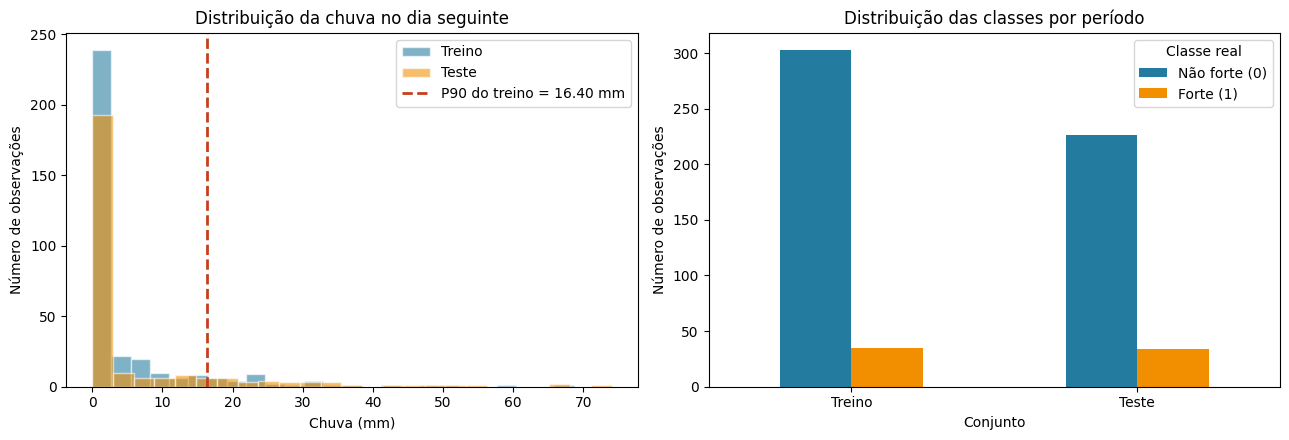

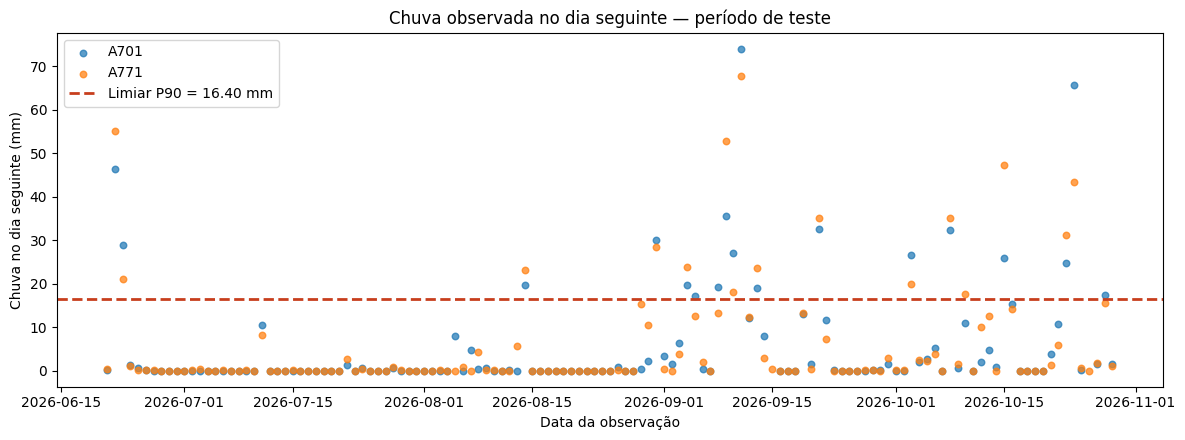

In [4]:
contagem_classes = pd.DataFrame({
    'Treino': y_treino.value_counts().reindex([0, 1], fill_value=0),
    'Teste': y_teste.value_counts().reindex([0, 1], fill_value=0),
})
contagem_classes.index = ['Não forte (0)', 'Forte (1)']

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
cores = {'Treino': '#247BA0', 'Teste': '#F18F01'}

for nome, conjunto in [('Treino', treino), ('Teste', teste)]:
    eixos[0].hist(
        conjunto[alvo_continuo], bins=25, alpha=0.58, label=nome,
        color=cores[nome], edgecolor='white'
    )
eixos[0].axvline(
    limiar_chuva_forte_mm, color='#C73E1D', linestyle='--', linewidth=2,
    label=f'P90 do treino = {limiar_chuva_forte_mm:.2f} mm'
)
eixos[0].set(title='Distribuição da chuva no dia seguinte', xlabel='Chuva (mm)', ylabel='Número de observações')
eixos[0].legend()

contagem_classes.T.plot(kind='bar', ax=eixos[1], color=['#247BA0', '#F18F01'])
eixos[1].set(title='Distribuição das classes por período', xlabel='Conjunto', ylabel='Número de observações')
eixos[1].tick_params(axis='x', rotation=0)
eixos[1].legend(title='Classe real')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
for estacao in sorted(teste['estacao'].unique()):
    dados_estacao = teste.loc[teste['estacao'] == estacao].sort_values('data')
    ax.scatter(
        dados_estacao['data'], dados_estacao[alvo_continuo],
        s=22, alpha=0.72, label=estacao
    )
ax.axhline(
    limiar_chuva_forte_mm, color='#C73E1D', linestyle='--', linewidth=2,
    label=f'Limiar P90 = {limiar_chuva_forte_mm:.2f} mm'
)
ax.set(title='Chuva observada no dia seguinte — período de teste', xlabel='Data da observação', ylabel='Chuva no dia seguinte (mm)')
ax.legend()
fig.tight_layout()
plt.show()

## Modelos, métricas e gráficos de avaliação

Comparamos um baseline de classe majoritária com regressão logística (modelo principal autorizado) e floresta aleatória como referência secundária. O pré-processamento é ajustado em cada pipeline somente com o treino. As saídas incluem métricas, matrizes de confusão e curvas ROC no teste. Como a classe forte é minoritária, interpretamos precisão, revocação e F1 além da ROC-AUC; o conjunto de teste é pequeno, então cada acerto ou erro afeta as métricas.

,precisao,revocacao,f1,roc_auc,acuracia_balanceada
modelo,,,,,
Maioria (baseline),0.000,0.000,0.000,0.500,0.500
Regressão logística,0.231,0.088,0.128,0.662,0.522
Floresta aleatória,0.000,0.000,0.000,0.722,0.500


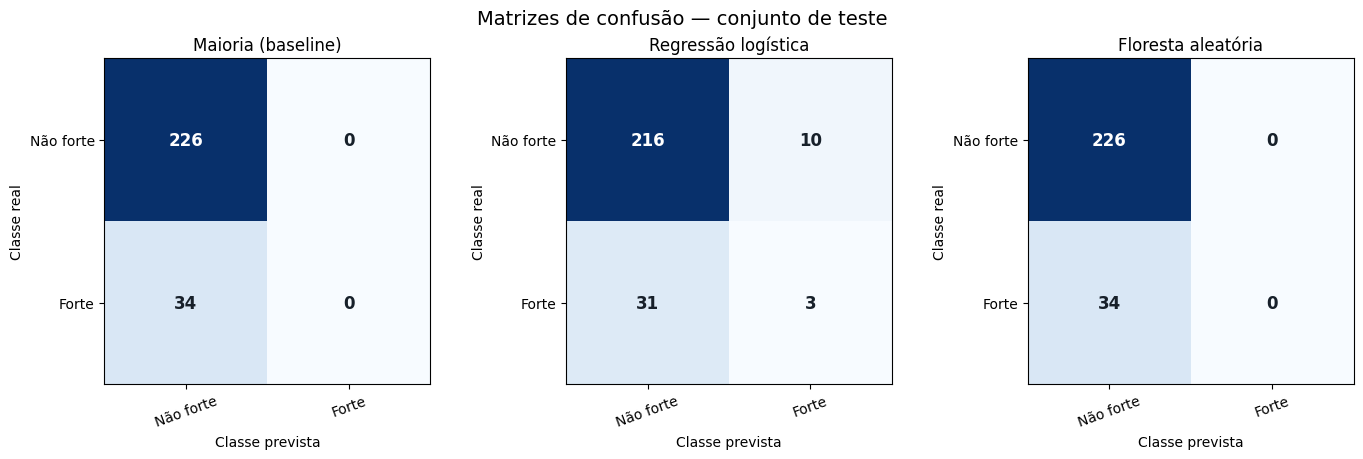

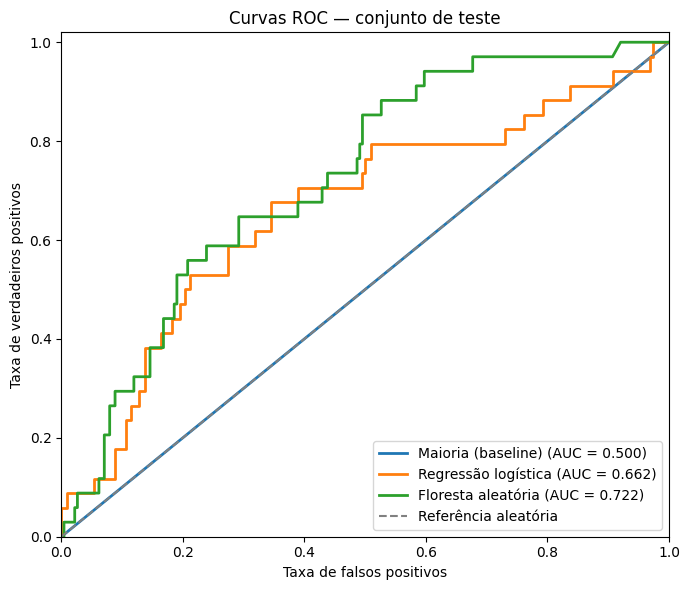

Gráficos PNG salvos em: C:\Users\user\Downloads\AVIVA_v13_Design_Unificado_Desktop_Android\ENTREGAS_FIAP\04_ML\graficos
Arquivos: 01_eda_distribuicao.png, 02_serie_temporal_teste.png, 03_matrizes_confusao.png, 04_curvas_roc.png


In [5]:
colunas_categoricas = ['estacao']
colunas_numericas = [
    coluna for coluna in X_treino.columns
    if coluna not in colunas_categoricas
]

preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', Pipeline([
            ('imputacao', SimpleImputer(strategy='median')),
            ('escala', StandardScaler()),
        ]), colunas_numericas),
        ('categoricas', Pipeline([
            ('imputacao', SimpleImputer(strategy='most_frequent')),
            ('codificacao', OneHotEncoder(handle_unknown='ignore')),
        ]), colunas_categoricas),
    ]
)

modelos = {
    'Maioria (baseline)': DummyClassifier(strategy='most_frequent'),
    'Regressão logística': Pipeline([
        ('preprocessamento', preprocessador),
        ('classificador', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
    ]),
    'Floresta aleatória': Pipeline([
        ('preprocessamento', preprocessador),
        ('classificador', RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=42,
        )),
    ]),
}

resultados = []
previsoes_modelos = {}
probabilidades_modelos = {}
matrizes_confusao = {}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)
    probabilidades = modelo.predict_proba(X_teste)[:, 1]
    previsoes_modelos[nome] = previsoes
    probabilidades_modelos[nome] = probabilidades
    resultados.append({
        'modelo': nome,
        'precisao': precision_score(y_teste, previsoes, zero_division=0),
        'revocacao': recall_score(y_teste, previsoes, zero_division=0),
        'f1': f1_score(y_teste, previsoes, zero_division=0),
        'roc_auc': roc_auc_score(y_teste, probabilidades),
        'acuracia_balanceada': balanced_accuracy_score(y_teste, previsoes),
    })
    matrizes_confusao[nome] = confusion_matrix(y_teste, previsoes, labels=[0, 1])

metricas = pd.DataFrame(resultados).set_index('modelo')
display(metricas.round(3))

fig, eixos = plt.subplots(1, len(modelos), figsize=(14, 4.5))
for ax, (nome, matriz) in zip(eixos, matrizes_confusao.items()):
    imagem = ax.imshow(matriz, cmap='Blues')
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_xticks([0, 1], labels=['Não forte', 'Forte'], rotation=20)
    ax.set_yticks([0, 1], labels=['Não forte', 'Forte'])
    limite = matriz.max() / 2
    for linha in range(2):
        for coluna in range(2):
            ax.text(
                coluna, linha, str(matriz[linha, coluna]),
                ha='center', va='center',
                color='white' if matriz[linha, coluna] > limite else '#17202A',
                fontsize=12, fontweight='bold'
            )
fig.suptitle('Matrizes de confusão — conjunto de teste', fontsize=14)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for nome, probabilidades in probabilidades_modelos.items():
    taxa_falso_positivo, taxa_verdadeiro_positivo, _ = roc_curve(y_teste, probabilidades)
    auc_modelo = roc_auc_score(y_teste, probabilidades)
    ax.plot(
        taxa_falso_positivo, taxa_verdadeiro_positivo, linewidth=2,
        label=f'{nome} (AUC = {auc_modelo:.3f})'
    )
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Referência aleatória')
ax.set(
    title='Curvas ROC — conjunto de teste',
    xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos',
    xlim=(0, 1), ylim=(0, 1.02)
)
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

# Exporta gráficos PNG para documentação e comparação dos resultados.
raiz_projeto = caminho_csv.parents[4]
if (raiz_projeto / 'ENTREGAS_FIAP').is_dir():
    pasta_graficos = raiz_projeto / 'ENTREGAS_FIAP' / '04_ML' / 'graficos'
else:
    pasta_graficos = Path.cwd() / 'graficos_ml'
pasta_graficos.mkdir(parents=True, exist_ok=True)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, conjunto in [('Treino', treino), ('Teste', teste)]:
    eixos[0].hist(conjunto[alvo_continuo], bins=25, alpha=0.58, label=nome, color=cores[nome], edgecolor='white')
eixos[0].axvline(limiar_chuva_forte_mm, color='#C73E1D', linestyle='--', linewidth=2, label=f'P90 = {limiar_chuva_forte_mm:.2f} mm')
eixos[0].set(title='Distribuição da chuva no dia seguinte', xlabel='Chuva (mm)', ylabel='Número de observações')
eixos[0].legend()
contagem_classes.T.plot(kind='bar', ax=eixos[1], color=['#247BA0', '#F18F01'])
eixos[1].set(title='Distribuição das classes por período', xlabel='Conjunto', ylabel='Número de observações')
eixos[1].tick_params(axis='x', rotation=0)
eixos[1].legend(title='Classe real')
fig.tight_layout()
fig.savefig(pasta_graficos / '01_eda_distribuicao.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 4.5))
for estacao in sorted(teste['estacao'].unique()):
    dados_estacao = teste.loc[teste['estacao'] == estacao].sort_values('data')
    ax.scatter(dados_estacao['data'], dados_estacao[alvo_continuo], s=22, alpha=0.72, label=estacao)
ax.axhline(limiar_chuva_forte_mm, color='#C73E1D', linestyle='--', linewidth=2, label=f'P90 = {limiar_chuva_forte_mm:.2f} mm')
ax.set(title='Chuva observada no dia seguinte — período de teste', xlabel='Data da observação', ylabel='Chuva no dia seguinte (mm)')
ax.legend()
fig.tight_layout()
fig.savefig(pasta_graficos / '02_serie_temporal_teste.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, eixos = plt.subplots(1, len(modelos), figsize=(14, 4.5))
for ax, (nome, matriz) in zip(eixos, matrizes_confusao.items()):
    ax.imshow(matriz, cmap='Blues')
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_xticks([0, 1], labels=['Não forte', 'Forte'], rotation=20)
    ax.set_yticks([0, 1], labels=['Não forte', 'Forte'])
    limite = matriz.max() / 2
    for linha in range(2):
        for coluna in range(2):
            ax.text(coluna, linha, str(matriz[linha, coluna]), ha='center', va='center', color='white' if matriz[linha, coluna] > limite else '#17202A', fontsize=12, fontweight='bold')
fig.suptitle('Matrizes de confusão — conjunto de teste', fontsize=14)
fig.tight_layout()
fig.savefig(pasta_graficos / '03_matrizes_confusao.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 6))
for nome, probabilidades in probabilidades_modelos.items():
    taxa_falso_positivo, taxa_verdadeiro_positivo, _ = roc_curve(y_teste, probabilidades)
    auc_modelo = roc_auc_score(y_teste, probabilidades)
    ax.plot(taxa_falso_positivo, taxa_verdadeiro_positivo, linewidth=2, label=f'{nome} (AUC = {auc_modelo:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Referência aleatória')
ax.set(title='Curvas ROC — conjunto de teste', xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(pasta_graficos / '04_curvas_roc.png', dpi=180, bbox_inches='tight')
plt.close(fig)
print('Gráficos PNG salvos em:', pasta_graficos.resolve())
print('Arquivos:', ', '.join(sorted(p.name for p in pasta_graficos.glob('*.png'))))

## Limitações e interpretação

Este é um primeiro baseline, não uma validação operacional. São apenas 598 dias-estação de duas estações e menos de um ano; treino e teste pertencem a períodos sazonais diferentes. Além disso, o percentil 90 foi estimado em um treino curto e a quantidade de casos fortes no teste é limitada. Não use essas métricas como garantia de desempenho em outras estações, anos ou localidades. Uma próxima etapa deve aumentar o período e a cobertura geográfica e avaliar estabilidade temporal antes de qualquer uso real.